# 11 – L2 P&L

What the L1 positions would have made, holding into imbalance: p MW left open for the ISP, bought at day-ahead and settled at the first-print imbalance price, so p × 0.25 h × (imbalance − day-ahead) EUR. Slippage EUR 2/MWh on every held MWh (stated assumption); the adopted limits (notes/limits.md): 10 MW, EUR 5,000 daily loss limit, flat for the rest of the Copenhagen day after a breach. **ar(1)**, the replay's winner, against **persistence**, 1 Oct 2025 – 30 Sep 2026, walk-forward on estimated vintages: the replay, not the record.

| card | |
|---|---|
| estimation window | ar(1): φ and μ refit on the 7 days before each freeze; positions: the rolling week of past calls |
| last refit | every freeze (continuous) |
| out-of-sample | yes: walk-forward, nothing fitted on the window scored |
| benchmark | persistence, the same construction |
| exceptions | loss-limit breaches, counted below |
| structural break | 4 Mar 2026 (SatisfiedDemand: demand → activated); the fractionation splits on it |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from nordcast import pnl, positions
from nordcast.layers.backtest import fractionate

D = Path("../data/layers")
NAVY, BLUE, GREY, BAND = "#0F2A4A", "#1F5FBF", "#7D8996", "#DCE3EC"
plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": BAND,
    }
)
LABEL = {"forecast": "ar(1)", "persistence": "persistence (control)"}

runs, rows = {}, []
for h in (15, 30, 60):
    c = pd.read_parquet(D / f"calls_h{h}.parquet").set_index("target", drop=False)
    for name in ("forecast", "persistence"):
        frame, breaches = pnl.run(positions.build_positions(name, c, h), c)
        runs[(h, name)] = (frame, c)
        mae = (
            (c.point - c.y).abs().mean()
            if name == "forecast"
            else (c.pers_point - c.y).abs().mean()
        )
        rows.append(
            {
                "h": h,
                "strategy": LABEL[name],
                "mae_mw": mae,
                **pnl.summary(frame, breaches),
            }
        )
card = pd.DataFrame(rows).set_index(["h", "strategy"])
card[
    [
        "net_eur",
        "gross_eur",
        "cost_eur",
        "mean_day_eur",
        "sharpe_daily_ann",
        "max_drawdown_eur",
        "mwh_traded",
        "eur_per_mwh",
        "positioned_isps",
        "unpriced_positioned_isps",
        "loss_limit_breaches",
        "mae_mw",
    ]
].round(2)

net_eur  gross_eur  cost_eur  mean_day_eur  \
h  strategy                                                              
15 ar(1)                    2894.79    3141.15    246.37          7.93   
   persistence (control)  144171.18  158264.57  14093.38        394.99   
30 ar(1)                    1169.48    1257.90     88.42          3.20   
   persistence (control)   88944.26  101230.63  12286.37        243.68   
60 ar(1)                     168.20     186.88     18.68          0.46   
   persistence (control)   61729.34   72209.75  10480.41        169.12   

                          sharpe_daily_ann  max_drawdown_eur  mwh_traded  \
h  strategy                                                                
15 ar(1)                              1.44           -997.14      123.18   
   persistence (control)              8.21          -5076.18     7046.69   
30 ar(1)                              2.90           -136.46       44.21   
   persistence (control)              4.74         -10447.02     6143.19   
60 ar(1)                              1.11            -88.24        9.34   
   persistence (control)              3.55          -8232.61     5240.21   

                          eur_per_mwh  positioned_isps  \
h  strategy                                              
15 ar(1)                        23.50              632   
   persistence (control)        20.46             5399   
30 ar(1)                        26.45              296   
   persistence (control)        14.48             4969   
60 ar(1)                        18.01               68   
   persistence (control)        11.78             4529   

                          unpriced_positioned_isps  loss_limit_breaches  \
h  strategy                                                               
15 ar(1)                                         0                    0   
   persistence (control)                         0                    0   
30 ar(1)                                         0                    0   
   persistence (control)                         0                    2   
60 ar(1)                                         0                    0   
   persistence (control)                         0                    2   

                          mae_mw  
h  strategy                       
15 ar(1)                  114.79  
   persistence (control)  140.54  
30 ar(1)                  116.85  
   persistence (control)  146.45  
60 ar(1)                  118.88  
   persistence (control)  152.71

**The number:** P&L per MW of MAE improvement, (net ar(1) − net persistence) / (MAE persistence − MAE ar(1)), EUR per MW. Positive means the forecast's skill turned into money; negative means it didn't, whatever its MAE.

In [2]:
number = {}
for h in (15, 30, 60):
    f, p = card.loc[(h, "ar(1)")], card.loc[(h, "persistence (control)")]
    number[h] = (f.net_eur - p.net_eur) / (p.mae_mw - f.mae_mw)
pd.Series(number, name="EUR per MW of MAE improvement").round(1)

15   -5485.5
30   -2965.8
60   -1819.7
Name: EUR per MW of MAE improvement, dtype: float64

## Attribution: direction against slippage (no carry or vol leg in this trade)

In [3]:
card[["gross_eur", "cost_eur", "net_eur"]].assign(
    cost_share=lambda x: x.cost_eur / x.gross_eur.abs()
).round(3)

gross_eur   cost_eur     net_eur  cost_share
h  strategy                                                            
15 ar(1)                    3141.155    246.368    2894.787       0.078
   persistence (control)  158264.566  14093.384  144171.182       0.089
30 ar(1)                    1257.899     88.416    1169.484       0.070
   persistence (control)  101230.632  12286.374   88944.258       0.121
60 ar(1)                     186.877     18.682     168.195       0.100
   persistence (control)   72209.751  10480.411   61729.339       0.145

## Where the money came from, 15 min (fractionation of net P&L per ISP)

In [4]:
frac = {}
for name in ("forecast", "persistence"):
    frame, c = runs[(15, name)]
    net = frame.net.dropna()
    net = net[frame.pos_mw.loc[net.index] != 0]
    frac[LABEL[name]] = fractionate(
        net,
        {
            "hour": c.hour,
            "onshore wind error at freeze (MW)": c.wind_onshore_err_da_last,
            "after 4 Mar 2026": c.regime_activated,
        },
        bins={
            "hour": 24,
            "onshore wind error at freeze (MW)": 5,
            "after 4 Mar 2026": 2,
        },
    )[["condition", "bin", "n", "mean", "share_of_total"]]
frac["persistence (control)"].round(3)

,condition,bin,n,mean,share_of_total
0,hour,0,133,23.567,0.022
1,hour,1,217,37.742,0.057
2,hour,2,145,29.930,0.030
3,hour,3,120,45.373,0.038
4,hour,4,150,25.204,0.026
5,hour,5,133,35.065,0.032
6,hour,6,138,22.660,0.022
7,hour,7,187,38.136,0.049
8,hour,8,220,30.514,0.047
9,hour,9,207,26.937,0.039


In [5]:
frac["ar(1)"].round(3)

,condition,bin,n,mean,share_of_total
0,hour,0,25,3.737,0.032
1,hour,1,21,5.600,0.041
2,hour,2,10,2.920,0.010
3,hour,3,16,6.100,0.034
4,hour,4,16,7.457,0.041
5,hour,5,11,4.803,0.018
6,hour,6,14,8.538,0.041
7,hour,7,28,9.995,0.097
8,hour,8,16,10.131,0.056
9,hour,9,15,10.871,0.056


## Cumulative P&L, 15 min, and the error behind it

MAE sits in its own panel, not on a second axis: the energy-analyst skill (a local Claude Code reference, kept out of git) treats a dual-axis overlay as a checklist, not evidence.

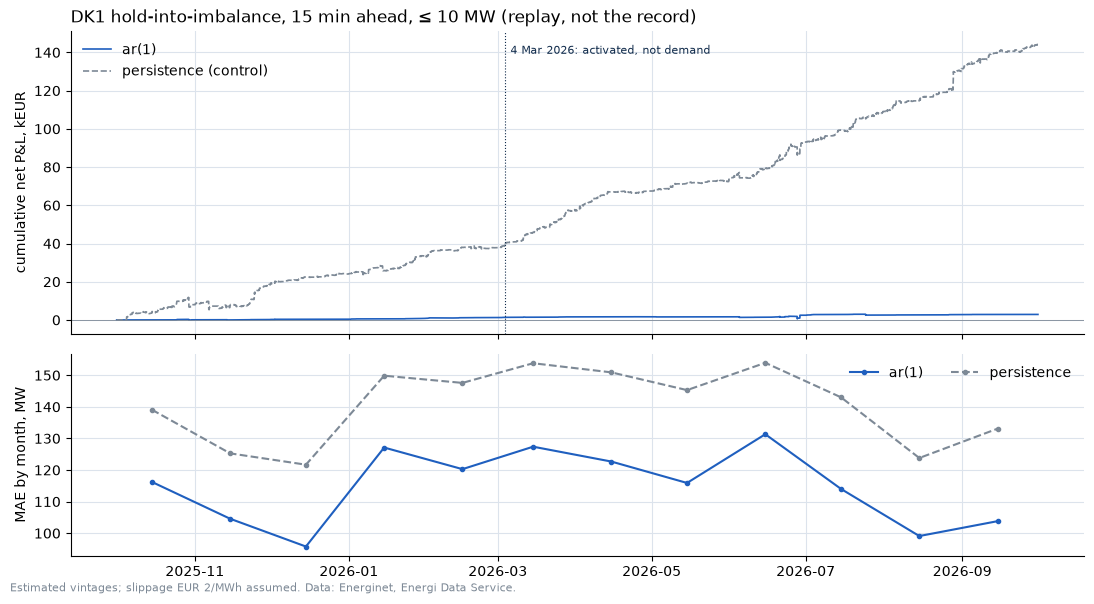

In [6]:
fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [3, 2]}
)
for name, colour, ls in (("forecast", BLUE, "-"), ("persistence", GREY, "--")):
    frame, c = runs[(15, name)]
    cum = frame.net.fillna(0).cumsum()
    top.plot(
        cum.index.tz_convert("Europe/Copenhagen"),
        cum / 1000,
        color=colour,
        ls=ls,
        lw=1.2,
        label=LABEL[name],
    )
top.axhline(0, color=GREY, lw=0.6)
top.axvline(
    pd.Timestamp("2026-03-04", tz="Europe/Copenhagen"), color=NAVY, lw=0.8, ls=":"
)
top.text(
    pd.Timestamp("2026-03-06", tz="Europe/Copenhagen"),
    top.get_ylim()[1] * 0.92,
    "4 Mar 2026: activated, not demand",
    fontsize=8,
    color=NAVY,
)
top.set_ylabel("cumulative net P&L, kEUR")
top.set_title(
    "DK1 hold-into-imbalance, 15 min ahead, ≤ 10 MW (replay, not the record)",
    loc="left",
)
top.legend(loc="upper left", frameon=False)
_, c = runs[(15, "forecast")]
month = (
    c.target.dt.tz_convert("Europe/Copenhagen").dt.tz_localize(None).dt.to_period("M")
)
for col, colour, ls, lab in (
    ("point", BLUE, "-", "ar(1)"),
    ("pers_point", GREY, "--", "persistence"),
):
    m = (c[col] - c.y).abs().groupby(month.to_numpy()).mean()
    bottom.plot(
        m.index.to_timestamp().tz_localize("Europe/Copenhagen") + pd.Timedelta(days=14),
        m,
        color=colour,
        ls=ls,
        marker="o",
        ms=3,
        label=lab,
    )
bottom.set_ylabel("MAE by month, MW")
bottom.legend(loc="upper right", frameon=False, ncol=2)
fig.text(
    0.01,
    0.005,
    "Estimated vintages; slippage EUR 2/MWh assumed. Data: Energinet, Energi Data Service.",
    fontsize=8,
    color=GREY,
)
fig.tight_layout()
fig.savefig("11_pnl.png", dpi=150, bbox_inches="tight")

## What this P&L is and isn't

A daily Sharpe of 8 for persistence at 15 min is not a strategy anyone could book. The calls only use what was published before each freeze, so it isn't leakage, but: the inputs are estimated vintages; EUR 2/MWh slippage is an assumption with no price impact; and a balance-responsible party is expected to aim for balance, so leaving a position open into imbalance on purpose runs against how the Danish balancing market is meant to be used (check Energinet's market regulations before treating it as a trade; not legal advice). Read the P&L as a measure of how well a call reads the system's direction, which is what the layer notes use it for, not as money on the table.

## Where the sources disagree

The layer notes ask for slippage "at the imbalance price" without a number; EUR 2/MWh is this layer's assumption, stated, and the cost share above shows how much it matters. The copied backtester charges costs on position changes; this trade is a fresh day-ahead purchase every ISP, so costs here are on every held MWh.